In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

In [3]:
df = pd.read_csv("../dataset/Mall_Customers.csv")

# Display the first five records and inspect the dataset.

display(df.head())
print("Dataset dimensions:", df.shape)
print("Column names:", df.columns.tolist())
print("\nData types:")
print(df.dtypes)
print("\nDescriptive statistics:")
display(df.describe(include="all"))

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


Dataset dimensions: (200, 5)
Column names: ['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']

Data types:
CustomerID                int64
Gender                      str
Age                       int64
Annual Income (k$)        int64
Spending Score (1-100)    int64
dtype: object

Descriptive statistics:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200,200.000000,200.000000,200.000000
unique,NaN,2,NaN,NaN,NaN
top,NaN,Female,NaN,NaN,NaN
freq,NaN,112,NaN,NaN,NaN
mean,100.500000,NaN,38.850000,60.560000,50.200000
std,57.879185,NaN,13.969007,26.264721,25.823522
min,1.000000,NaN,18.000000,15.000000,1.000000
25%,50.750000,NaN,28.750000,41.500000,34.750000
50%,100.500000,NaN,36.000000,61.500000,50.000000
75%,150.250000,NaN,49.000000,78.000000,73.000000


In [ ]:
# Check for missing values.
print("Missing values in each column:")
print(df.isnull().sum())

# Check duplicate rows and remove exact duplicates if any are found.
duplicate_count = df.duplicated().sum()
print("\nDuplicate rows:", duplicate_count)
if duplicate_count > 0:
    df = df.drop_duplicates()
    print("Duplicate rows removed.")
else:
    print("No duplicate rows found.")

# Inspect basic valid ranges; do not remove valid customers or outliers automatically.
print("\nNegative annual incomes:", (df["Annual Income (k$)"] < 0).sum())
print("Spending scores outside 1-100:", (~df["Spending Score (1-100)"].between(1, 100)).sum())

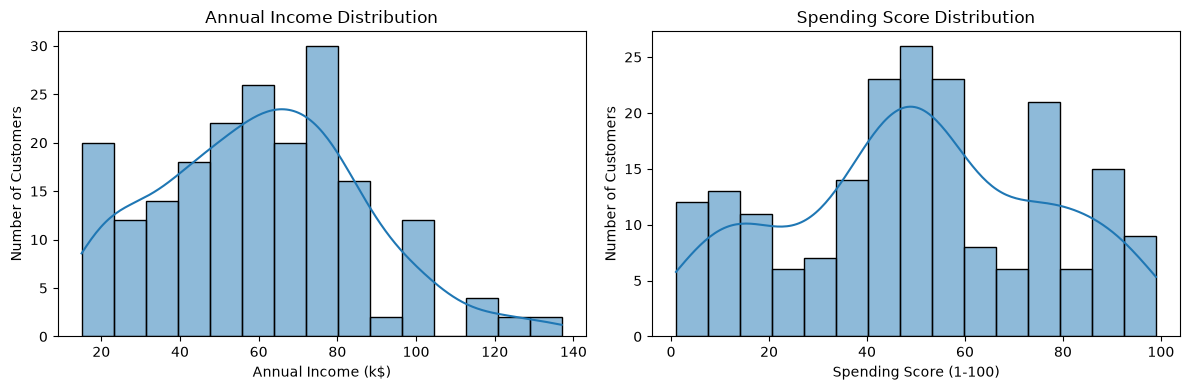

Interpretation: Review how customers are distributed across income and spending score values.


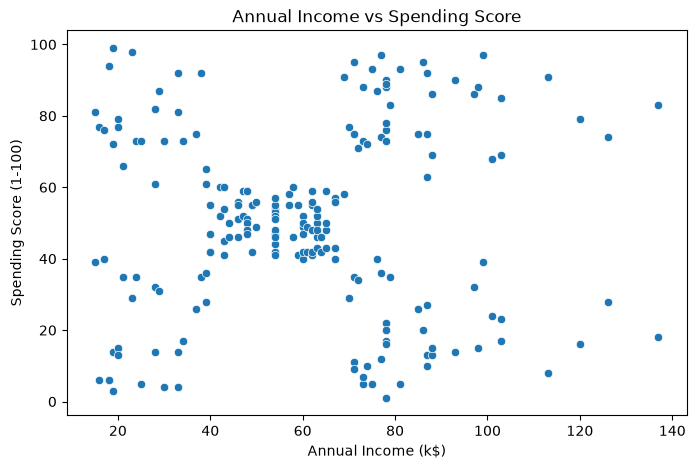

Interpretation: Look for visible patterns or groups in these two features.


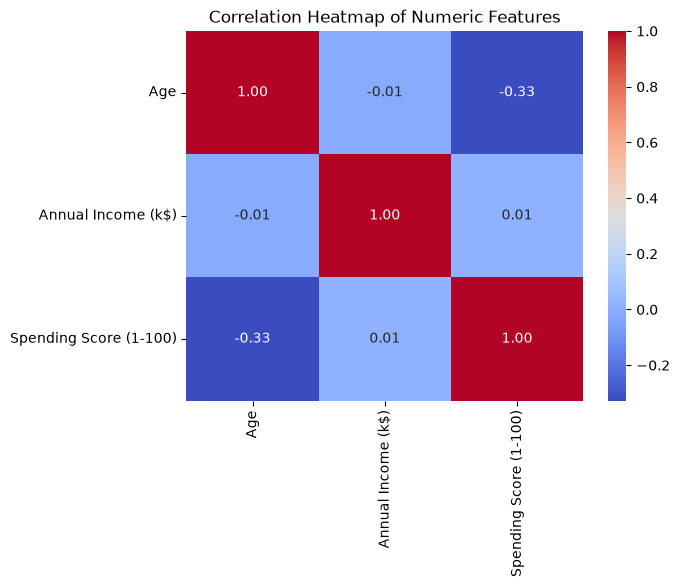

Interpretation: Correlation values describe linear relationships and range from -1 to 1.


In [4]:
# Annual income and spending score distributions.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=df, x="Annual Income (k$)", bins=15, kde=True, ax=axes[0])
axes[0].set_title("Annual Income Distribution")
axes[0].set_xlabel("Annual Income (k$)")
axes[0].set_ylabel("Number of Customers")

sns.histplot(data=df, x="Spending Score (1-100)", bins=15, kde=True, ax=axes[1])
axes[1].set_title("Spending Score Distribution")
axes[1].set_xlabel("Spending Score (1-100)")
axes[1].set_ylabel("Number of Customers")
plt.tight_layout()
plt.show()
print("Interpretation: Review how customers are distributed across income and spending score values.")

# Relationship between annual income and spending score.
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="Annual Income (k$)", y="Spending Score (1-100)")
plt.title("Annual Income vs Spending Score")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.show()
print("Interpretation: Look for visible patterns or groups in these two features.")

# Correlation heatmap for numeric data; CustomerID is only an identifier.
numeric_features = df.select_dtypes(include="number").drop(columns=["CustomerID"], errors="ignore")
sns.heatmap(numeric_features.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap of Numeric Features")
plt.show()
print("Interpretation: Correlation values describe linear relationships and range from -1 to 1.")

In [5]:
# Select the two customer features for clustering.
X = df[["Annual Income (k$)", "Spending Score (1-100)"]]

# CustomerID is excluded because it is only an identifier.
# There is no target variable because K-Means is unsupervised.
print("Selected features:")
print(X.head())
print("Feature data shape:", X.shape)

Selected features:
   Annual Income (k$)  Spending Score (1-100)
0                  15                      39
1                  15                      81
2                  16                       6
3                  16                      77
4                  17                      40
Feature data shape: (200, 2)


In [6]:
# K-Means uses distances, so features with larger numeric ranges can dominate.
# StandardScaler transforms each feature to approximately mean 0 and standard deviation 1.
# Formula: z = (x - mean) / standard deviation
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("First five scaled rows:")
display(pd.DataFrame(X_scaled, columns=X.columns).head())

First five scaled rows:


,Annual Income (k$),Spending Score (1-100)
0,-1.738999,-0.434801
1,-1.738999,1.195704
2,-1.700830,-1.715913
3,-1.700830,1.040418
4,-1.662660,-0.395980


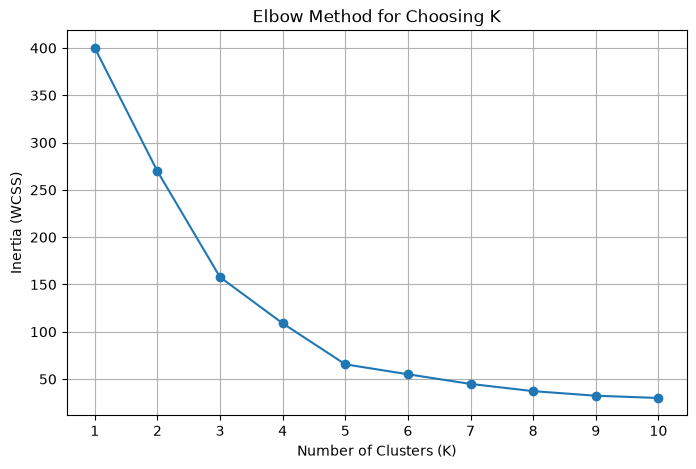

In [7]:
# Test K values from 1 to 10 and store each model's inertia.
wcss = []
for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

# Plot K against inertia (within-cluster sum of squares).
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker="o")
plt.title("Elbow Method for Choosing K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia (WCSS)")
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

# Look for the point where the decrease in inertia starts to slow.
# Do not choose K automatically; inspect the plotted curve.

Silhouette scores:
K=2: 0.321
K=3: 0.467
K=4: 0.494
K=5: 0.555
K=6: 0.540
K=7: 0.528
K=8: 0.455
K=9: 0.457
K=10: 0.443


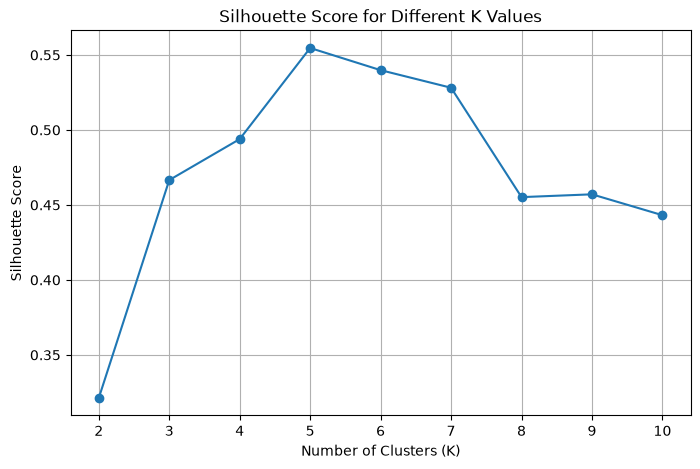

In [8]:
# Calculate silhouette scores for K values from 2 to 10.
silhouette_scores = []
k_values = range(2, 11)

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)

print("Silhouette scores:")
for k, score in zip(k_values, silhouette_scores):
    print(f"K={k}: {score:.3f}")

# Plot the scores so they can be compared with the Elbow graph.
plt.figure(figsize=(8, 5))
plt.plot(list(k_values), silhouette_scores, marker="o")
plt.title("Silhouette Score for Different K Values")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

# Higher scores generally indicate better-separated, more cohesive clusters.
# Compare the best scores with the elbow pattern before selecting K.

In [9]:
# Choose K=5 based on the elbow plot and silhouette-score comparison.
selected_k = 5

# K-Means initializes centroids, assigns customers to the nearest centroid,
# and updates centroids until cluster assignments stop changing.
final_kmeans = KMeans(
    n_clusters=selected_k,
    random_state=42,
    n_init=10,
)

# Fit the model and create a cluster label for each customer.
cluster_labels = final_kmeans.fit_predict(X_scaled)

print("Model trained with K =", selected_k)
print("First 10 cluster labels:", cluster_labels[:10])

Model trained with K = 5
First 10 cluster labels: [4 2 4 2 4 2 4 2 4 2]


In [10]:
# Add the model's cluster label to each customer's original record.
df["Cluster"] = cluster_labels

print("Dataset with cluster assignments:")
display(df.head())

print("Number of customers in each cluster:")
print(df["Cluster"].value_counts().sort_index())

Dataset with cluster assignments:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,4
1,2,Male,21,15,81,2
2,3,Female,20,16,6,4
3,4,Female,23,16,77,2
4,5,Female,31,17,40,4


Number of customers in each cluster:
Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


Cluster centroids in original units:


,Annual Income (k$),Spending Score (1-100)
0,55.296296,49.518519
1,86.538462,82.128205
2,25.727273,79.363636
3,88.200000,17.114286
4,26.304348,20.913043


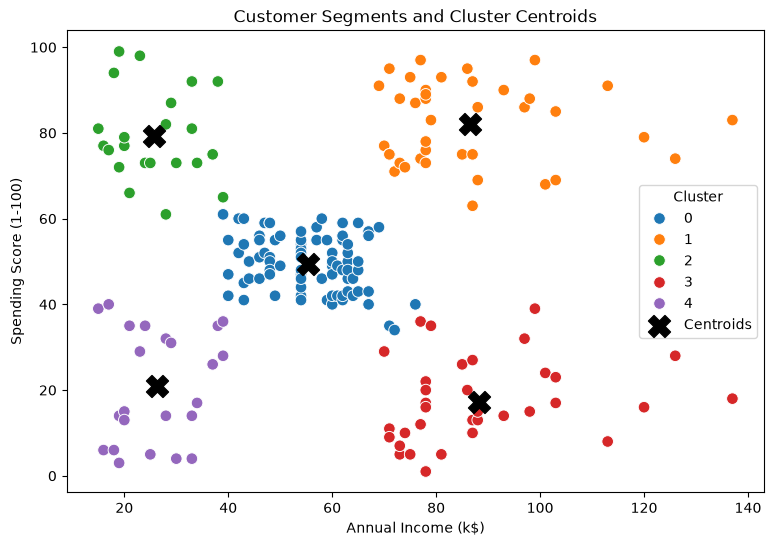

In [11]:
# Convert the model's scaled centroids back to the original feature units.
original_centroids = scaler.inverse_transform(final_kmeans.cluster_centers_)
centroids = pd.DataFrame(original_centroids, columns=X.columns)
print("Cluster centroids in original units:")
display(centroids)

# Plot customers by cluster and show each centroid with a black X.
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Cluster",
    palette="tab10",
    s=70,
)
plt.scatter(
    centroids["Annual Income (k$)"],
    centroids["Spending Score (1-100)"],
    marker="X",
    s=250,
    color="black",
    label="Centroids",
)
plt.title("Customer Segments and Cluster Centroids")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend(title="Cluster")
plt.show()

In [13]:
# Calculate average income, average spending score, and customer count per cluster.
cluster_summary = df.groupby("Cluster").agg(
    Average_Annual_Income=("Annual Income (k$)", "mean"),
    Average_Spending_Score=("Spending Score (1-100)", "mean"),
    Customer_Count=("Cluster", "size"),
)

print("Cluster summary:")
display(cluster_summary.round(2))

# Describe clusters using their measured averages relative to overall averages.
overall_income = df["Annual Income (k$)"].mean()
overall_spending = df["Spending Score (1-100)"].mean()

def compare_to_average(value, average):
    if value > average * 1.10:
        return "higher"
    if value < average * 0.90:
        return "lower"
    return "average"

for cluster, row in cluster_summary.iterrows():
    income_level = compare_to_average(row["Average_Annual_Income"], overall_income)
    spending_level = compare_to_average(row["Average_Spending_Score"], overall_spending)
    print(
        f"Cluster {cluster}: {income_level}-income, {spending_level}-spending "
        f"customers ({int(row['Customer_Count'])} customers)."
    )

Cluster summary:


,Average_Annual_Income,Average_Spending_Score,Customer_Count
Cluster,,,
0,55.30,49.52,81
1,86.54,82.13,39
2,25.73,79.36,22
3,88.20,17.11,35
4,26.30,20.91,23


Cluster 0: average-income, average-spending customers (81 customers).
Cluster 1: higher-income, higher-spending customers (39 customers).
Cluster 2: lower-income, higher-spending customers (22 customers).
Cluster 3: higher-income, lower-spending customers (35 customers).
Cluster 4: lower-income, lower-spending customers (23 customers).


In [14]:
# Evaluate the final clustering model.
final_inertia = final_kmeans.inertia_
final_silhouette = silhouette_score(X_scaled, cluster_labels)
cluster_counts = df["Cluster"].value_counts().sort_index()

print("Final model inertia:", round(final_inertia, 2))
print("Final silhouette score:", round(final_silhouette, 3))
print("Number of customers in each cluster:")
print(cluster_counts)

# These metrics summarize distances and separation; they do not measure business success.
print("\nLimitations: Inertia tends to decrease as K increases, and the silhouette score")
print("measures geometric separation, not whether the segments are useful to the business.")

Final model inertia: 65.57
Final silhouette score: 0.555
Number of customers in each cluster:
Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64

Limitations: Inertia tends to decrease as K increases, and the silhouette score
measures geometric separation, not whether the segments are useful to the business.


In [ ]:
# Save the fitted scaler and K-Means model so the Streamlit app can reuse them.
from pathlib import Path
import joblib

artifact_path = Path("week-2/segmentation_model.joblib")
if not artifact_path.parent.exists():
    artifact_path = Path("segmentation_model.joblib")

joblib.dump(
    {
        "scaler": scaler,
        "model": final_kmeans,
        "feature_columns": X.columns.tolist(),
        "selected_k": selected_k,
    },
    artifact_path,
)
print(f"Saved model and scaler to {artifact_path}")

In [15]:
# Save the customer data and assigned clusters to a CSV file.
df.to_csv("customer_segments.csv", index=False)
print("Customer segments exported to customer_segments.csv")

Customer segments exported to customer_segments.csv
